# The reverse direction

Does a Marathi probe help a Hindi probe when Hindi data is scarce? This is
`combine.ipynb` with the languages swapped: a Marathi probe trained on 800
sentences is combined with Hindi probes trained on 25 to 800 Hindi sentences,
and everything is scored on Hindi dev, with the Hindi test split scored once at
the end. Hindi is not really low-resource, so like the main experiment this
only simulates a small budget.

The main setting (layer 7, first-piece) is kept as it is, so the two directions
are comparable; it was chosen on Marathi dev, and nothing here is chosen on
Hindi dev or test.

In [1]:
import json
from collections import defaultdict
from pathlib import Path

import conllu
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
import numpy as np
import torch
import yaml
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupKFold
from statsmodels.stats.multitest import multipletests

ROOT = Path.cwd()
CONFIG = yaml.safe_load((ROOT / "config.yaml").read_text())
CACHE = ROOT / "data" / "cache"
samples = json.loads((CACHE / "samples.json").read_text())
LAYER, POOLING = CONFIG["main_setting"]["layer"], CONFIG["main_setting"]["pooling"]
HELPER_SENTENCES = CONFIG["reverse"]["marathi_train_sentences"]
sizes = CONFIG["reverse"]["hindi_train_sentences"]


class Split:
    """One split's cached features at the main setting, its labels (True = Nom) and its nouns by sentence."""

    def __init__(self, language: str, split: str):
        nouns = json.loads((CACHE / f"{language}_{split}_nouns.json").read_text())
        self.x = np.asarray(np.load(CACHE / f"{language}_{split}_{POOLING}.npy", mmap_mode="r")[LAYER])
        self.y = np.array([noun["label"] == "Nom" for noun in nouns])
        self.sentence = np.array([noun["sentence"] for noun in nouns])
        self.form = np.array([noun["form"] for noun in nouns])
        self.by_sentence = defaultdict(list)
        for k, noun in enumerate(nouns):
            self.by_sentence[noun["sentence"]].append(k)

    def rows(self, sentences) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        """Features, labels and sentence ids of the nouns in these sentences; a sentence listed twice is used twice."""
        keep = [k for s in sentences for k in self.by_sentence[s]]
        return self.x[keep], self.y[keep], self.sentence[keep]


marathi, hindi, dev, test = Split("mr", "train"), Split("hi", "train"), Split("hi", "dev"), Split("hi", "test")
majority = max(dev.y.mean(), 1 - dev.y.mean())
print(f"layer {LAYER}, {POOLING}-piece; Hindi dev: {len(dev.y)} nouns, majority {majority:.3f}")

layer 7, first-piece; Hindi dev: 7923 nouns, majority 0.540


## Methods

The same methods as in `combine.ipynb`, with the roles swapped. With a budget of
n labelled Hindi sentences:

- **Marathi probe:** trained on the first 800 sentences of the seed's Marathi
  order only.
- **Hindi probe:** trained on 80% of the n sentences, and again on all n.
- **Pooled:** one probe trained on the Marathi sentences plus all n Hindi sentences.
- **Weight blend:** the Marathi and Hindi (80%) probes, each scaled to length 1,
  mixed in one fixed proportion learned on the other 20%, with a shared scale
  and bias.
- **Router:** the same, but the proportion depends on the noun.
- **Hindi + Hindi control:** the blend and the router with the Marathi probe
  swapped for a second Hindi probe trained on a resample of the same 80%.

Every probe chooses its regularisation strength (C) by 5-fold cross-validation
over its own training sentences.

In [2]:
PENALTIES = [None, 1e4, 1e3, 1e2, 1e1, 1.0, 0.1, 0.01]
CS = [0.001, 0.01, 0.1, 1.0, 10.0]


def probe(x: np.ndarray, y: np.ndarray, groups: np.ndarray) -> LogisticRegressionCV:
    """Train a probe, choosing C by 5-fold cross-validation that keeps each sentence's nouns together."""
    folds = list(GroupKFold(n_splits=5).split(x, y, groups))
    return LogisticRegressionCV(Cs=CS, cv=folds, scoring="neg_log_loss", max_iter=5000).fit(x, y)


def unit(model: LogisticRegression) -> np.ndarray:
    w = model.coef_[0]
    return w / np.linalg.norm(w)


def gate(mix, x) -> np.ndarray:
    """The share g = sigmoid(v·h + c) that the mix gives probe a on each noun."""
    c, _, _, v = mix
    return 1 / (1 + np.exp(-(x @ v + c)))


def logits(mix, x, s_a, s_b) -> np.ndarray:
    """a·(g·s_a + (1 − g)·s_b) + b."""
    _, a, b, _ = mix
    g = gate(mix, x)
    return a * (g * s_a + (1 - g) * s_b) + b


def fit_mix(x, s_a, s_b, y, penalty=None, start=(0.0, 1.0, 0.0)):
    """Learn (c, a, b, v) of `logits` from two probes' scores s_a and s_b.

    With penalty None, v stays 0 and every noun gets the same mix (the weight
    blend); otherwise v is learned with an L2 penalty of that strength (the
    router). Like scikit-learn's C=1, the loss is the summed log loss plus a²/2.
    """
    x, s_a, s_b, y = (torch.as_tensor(t, dtype=torch.float64) for t in (x, s_a, s_b, y))
    c, a, b = (torch.tensor(float(t), dtype=torch.float64, requires_grad=True) for t in start)
    v = torch.zeros(x.shape[1], dtype=torch.float64, requires_grad=penalty is not None)
    optimiser = torch.optim.LBFGS([c, a, b] + ([v] if penalty is not None else []),
                                  max_iter=500, line_search_fn="strong_wolfe")

    def closure():
        optimiser.zero_grad()
        g = torch.sigmoid(x @ v + c)
        out = a * (g * s_a + (1 - g) * s_b) + b
        loss = torch.nn.functional.binary_cross_entropy_with_logits(out, y, reduction="sum") + a * a / 2
        if penalty is not None:
            loss = loss + penalty * (v @ v) / 2
        loss.backward()
        return loss

    optimiser.step(closure)
    return c.item(), a.item(), b.item(), v.detach().numpy()


def combine(w_a: np.ndarray, w_b: np.ndarray, x: np.ndarray, y: np.ndarray, groups: np.ndarray):
    """Fit the weight blend and the router of two length-1 probes on these nouns (groups = their sentences)."""
    order = {group: i for i, group in enumerate(dict.fromkeys(groups))}
    k = min(5, len(order))
    fold = np.array([order[group] % k for group in groups])
    s_a, s_b = x @ w_a, x @ w_b
    blend = fit_mix(x, s_a, s_b, y)

    def held_out_loss(penalty):
        loss = 0.0
        for f in range(k):
            train, held = fold != f, fold == f
            mix = fit_mix(x[train], s_a[train], s_b[train], y[train], penalty, blend[:3])
            z = logits(mix, x[held], s_a[held], s_b[held])
            loss += np.logaddexp(0, -np.where(y[held], z, -z)).sum()
        return loss

    penalty = min(PENALTIES, key=held_out_loss)
    router = blend if penalty is None else fit_mix(x, s_a, s_b, y, penalty, blend[:3])
    return blend, router, penalty

## Sweep

For each seed, the Hindi budget is the first n of the seed's 800 Hindi
sentences, so smaller budgets sit inside larger ones. The first 80% trains the
Hindi probes and the last 20% is held out for the blend and the router. Every
probe is scored on Hindi dev and Hindi test at once; only dev is looked at until
the final section.

In [3]:
def sweep():
    """Run every method for each seed and Hindi budget.

    Returns {"dev": (runs, correct, gates), "test": ...}, where correct[seed, n][method]
    says which nouns the method got right and gates[seed, n] is the Marathi share
    the router gives each noun.
    """
    share = CONFIG["router_share"]
    splits = {"dev": dev, "test": test}
    out = {name: ([], {}, {}) for name in splits}
    for seed in map(str, CONFIG["seeds"]):
        rng = np.random.default_rng(int(seed))
        marathi_x, marathi_y, marathi_g = marathi.rows(samples["mr"][seed][:HELPER_SENTENCES])
        marathi_probe = probe(marathi_x, marathi_y, marathi_g)
        for n in sizes:
            budget = samples["hi"][seed][:n]
            cut = round(n * (1 - share))
            probe_part, router_part = budget[:cut], budget[cut:]
            hindi_probe = probe(*hindi.rows(probe_part))
            resampled_probe = probe(*hindi.rows(rng.choice(probe_part, len(probe_part))))
            hindi_x, hindi_y, hindi_g = hindi.rows(budget)
            # Marathi sentence ids are made negative so they never share a fold with Hindi ones.
            probes = {
                "marathi": marathi_probe,
                "hindi_80": hindi_probe,
                "hindi_100": probe(hindi_x, hindi_y, hindi_g),
                "pooled": probe(np.vstack([marathi_x, hindi_x]), np.concatenate([marathi_y, hindi_y]),
                                np.concatenate([-1 - marathi_g, hindi_g])),
            }
            info = {"seed": int(seed), "n": n} | {f"C_{name}": float(model.C_[0]) for name, model in probes.items()}
            router_x, router_y, router_g = hindi.rows(router_part)
            mixes = {}
            for name, other in [("mh", marathi_probe), ("hh", resampled_probe)]:
                w_a, w_b = unit(other), unit(hindi_probe)
                blend, router, penalty = combine(w_a, w_b, router_x, router_y, router_g)
                mixes[name] = w_a, w_b, blend, router
                info[f"other_share_{name}"] = 1 / (1 + np.exp(-blend[0]))
                info[f"penalty_{name}"] = penalty
            info["cos_marathi_hindi"] = float(unit(marathi_probe) @ unit(hindi_probe))
            info["cos_hindi_resample"] = float(unit(resampled_probe) @ unit(hindi_probe))
            for split_name, split in splits.items():
                right = {name: model.predict(split.x) == split.y for name, model in probes.items()}
                for name, (w_a, w_b, blend, router) in mixes.items():
                    s_a, s_b = split.x @ w_a, split.x @ w_b
                    right[f"blend_{name}"] = (logits(blend, split.x, s_a, s_b) > 0) == split.y
                    right[f"router_{name}"] = (logits(router, split.x, s_a, s_b) > 0) == split.y
                # Binary labels, so a wrong answer is the other class.
                f1 = {f"f1_{method}": f1_score(split.y, np.where(hits, split.y, ~split.y), average="macro")
                      for method, hits in right.items()}
                runs, correct, gates = out[split_name]
                runs.append(info | {method: hits.mean() for method, hits in right.items()} | f1)
                correct[int(seed), n] = right
                gates[int(seed), n] = gate(mixes["mh"][3], split.x)
            run = out["dev"][0][-1]
            print(f"seed {seed}, n {n:3d}: " + ", ".join(
                f"{key} {run[key]:.3f}" for key in ["hindi_100", "pooled", "blend_mh", "router_mh"]), flush=True)
    return out


by_split = sweep()
runs, correct, gates = by_split["dev"]

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

seed 13, n  25: hindi_100 0.795, pooled 0.855, blend_mh 0.797, router_mh 0.797


/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

... (137 outputs left out)

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

seed 89, n 800: hindi_100 0.920, pooled 0.910, blend_mh 0.915, router_mh 0.916


## Results

Mean ± standard deviation over the five seeds, on Hindi dev. `other share` is
the part of the blend given to the Marathi probe (or to the second Hindi probe
in the control).

Accuracy
n                                            25             50            100            200            400            800
Marathi probe                       0.851 ±0.008    0.851 ±0.008    0.851 ±0.008    0.851 ±0.008    0.851 ±0.008    0.851 ±0.008
Hindi probe, 80%                    0.777 ±0.015    0.831 ±0.006    0.864 ±0.005    0.889 ±0.003    0.905 ±0.002    0.915 ±0.001
Hindi probe, all n                  0.794 ±0.011    0.842 ±0.004    0.873 ±0.006    0.893 ±0.002    0.908 ±0.002    0.918 ±0.001
Pooled data                         0.865 ±0.006    0.873 ±0.005    0.884 ±0.005    0.894 ±0.005    0.905 ±0.003    0.914 ±0.003
Blend, Marathi + Hindi              0.824 ±0.041    0.857 ±0.009    0.878 ±0.005    0.895 ±0.006    0.908 ±0.002    0.917 ±0.002
Router, Marathi + Hindi             0.822 ±0.038    0.863 ±0.006    0.882 ±0.003    0.892 ±0.007    0.908 ±0.002    0.917 ±0.002
Blend, Hindi + Hindi                0.723 ±0.063    0.827 ±0.011    0.859 ±0.004    0.888 ±0.0

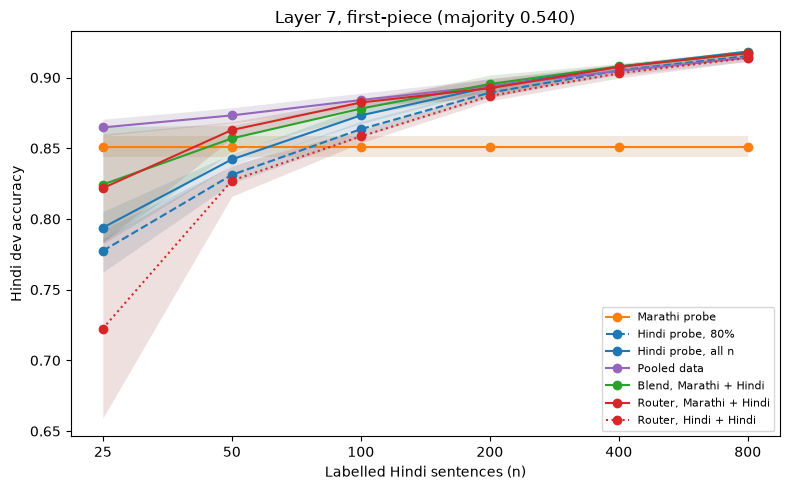

In [4]:
methods = {
    "marathi": "Marathi probe",
    "hindi_80": "Hindi probe, 80%",
    "hindi_100": "Hindi probe, all n",
    "pooled": "Pooled data",
    "blend_mh": "Blend, Marathi + Hindi",
    "router_mh": "Router, Marathi + Hindi",
    "blend_hh": "Blend, Hindi + Hindi",
    "router_hh": "Router, Hindi + Hindi",
    "other_share_mh": "Marathi share of blend",
    "other_share_hh": "2nd Hindi share of blend",
}
scored = [key for key in methods if not key.startswith("other_share")]
cosines = {"cos_marathi_hindi": "cosine, Marathi vs Hindi (80%)",
           "cos_hindi_resample": "cosine, Hindi vs its resample"}


def summarise(runs: list[dict], keys: list[str]) -> dict:
    return {key: {n: {"mean": np.mean([r[key] for r in runs if r["n"] == n]),
                      "std": np.std([r[key] for r in runs if r["n"] == n])} for n in sizes} for key in keys}


def show(summary: dict, labels: dict) -> None:
    print(f"{'n':32s}" + "".join(f"{n:>15d}" for n in sizes))
    for key, label in labels.items():
        print(f"{label:32s}" + "".join(f"{summary[key][n]['mean']:9.3f} ±{summary[key][n]['std']:.3f}" for n in sizes))


summary = summarise(runs, list(methods) + list(cosines))
f1_summary = summarise(runs, [f"f1_{key}" for key in scored])
(ROOT / "results" / "reverse.json").write_text(json.dumps(
    {"layer": LAYER, "pooling": POOLING, "split": "hi dev", "majority": majority,
     "summary": summary, "macro_f1": f1_summary, "runs": runs}, indent=2) + "\n")

print("Accuracy")
show(summary, methods | cosines)
print("\nMacro-F1")
show(f1_summary, {f"f1_{key}": methods[key] for key in scored})
print("\nRouter penalty chosen (None = fell back to the blend):")
for name in ["mh", "hh"]:
    print(f"  {name}:", {n: [r[f"penalty_{name}"] for r in runs if r["n"] == n] for n in sizes})

figure, ax = plt.subplots(figsize=(8, 5))
lines = [("marathi", "C1", "-"), ("hindi_80", "C0", "--"), ("hindi_100", "C0", "-"),
         ("pooled", "C4", "-"), ("blend_mh", "C2", "-"), ("router_mh", "C3", "-"), ("router_hh", "C3", ":")]
for key, color, style in lines:
    mean = np.array([summary[key][n]["mean"] for n in sizes])
    std = np.array([summary[key][n]["std"] for n in sizes])
    # The band is the line's colour mixed half-way with grey.
    band = 0.5 * np.array(to_rgb(color)) + 0.5 * np.array(to_rgb("grey"))
    ax.fill_between(sizes, mean - std, mean + std, color=band, alpha=0.18, linewidth=0)
    ax.plot(sizes, mean, color=color, linestyle=style, marker="o", label=methods[key])
ax.set(xscale="log", xticks=sizes, xticklabels=sizes, xlabel="Labelled Hindi sentences (n)",
       ylabel="Hindi dev accuracy", title=f"Layer {LAYER}, {POOLING}-piece (majority {majority:.3f})")
ax.minorticks_off()
ax.legend(fontsize=8)
figure.tight_layout()
figure.savefig(ROOT / "results" / "reverse.png", dpi=150)
plt.show()

## Are the differences real?

The same paired tests as in `combine.ipynb`: the sentence is the unit that gets
resampled, the interval comes from 10,000 bootstrap resamples, p from randomly
swapping the two methods' answers sentence by sentence, Holm p corrects for
running all the comparisons at once, and seeds won counts the seeds in which the
first method scored higher.

In [5]:
comparisons = [
    ("blend_mh", "hindi_100"),   # does the blend beat Hindi alone with the same data?
    ("router_mh", "blend_mh"),   # does choosing per noun add anything?
    ("blend_mh", "pooled"),      # is blending better than pooling the data?
    ("blend_hh", "hindi_100"),   # control: does combining help without Marathi?
]
seeds = [int(seed) for seed in CONFIG["seeds"]]


def significance(correct: dict, split: Split, path: Path) -> list[dict]:
    """Paired tests of each comparison at each budget, resampling the split's sentences."""
    sentence = np.unique(split.sentence, return_inverse=True)[1]
    nouns_per_sentence = np.bincount(sentence)
    rng = np.random.default_rng(0)
    draws = rng.integers(0, len(nouns_per_sentence), (10_000, len(nouns_per_sentence)))
    flips = rng.choice([-1.0, 1.0], draws.shape)
    rows = []
    for a, b in comparisons:
        for n in sizes:
            # Per sentence: right answers of a minus those of b, averaged over the seeds.
            diff = np.mean([np.bincount(sentence, correct[seed, n][a] * 1.0 - correct[seed, n][b])
                            for seed in seeds], axis=0)
            observed = diff.sum() / len(sentence)
            boot = diff[draws].sum(1) / nouns_per_sentence[draws].sum(1)
            swapped = (flips * diff).sum(1) / len(sentence)
            rows.append({
                "a": a, "b": b, "n": n, "difference": observed,
                "low": np.percentile(boot, 2.5), "high": np.percentile(boot, 97.5),
                "p": (np.sum(np.abs(swapped) >= abs(observed)) + 1) / (len(swapped) + 1),
                "seeds_won": int(sum(correct[seed, n][a].mean() > correct[seed, n][b].mean() for seed in seeds)),
            })
    for row, holm in zip(rows, multipletests([row["p"] for row in rows], method="holm")[1]):
        row["holm_p"] = holm
    path.write_text(json.dumps(rows, indent=2) + "\n")

    print(f"{'comparison':52s}{'n':>5s}{'difference':>12s}{'95% interval':>18s}{'p':>9s}{'Holm p':>9s}{'seeds won':>11s}")
    for t in rows:
        print(f"{methods[t['a']] + ' vs ' + methods[t['b']]:52s}{t['n']:5d}{100 * t['difference']:+11.1f} "
              f"  [{100 * t['low']:+5.1f}, {100 * t['high']:+5.1f}]{t['p']:9.4f}{t['holm_p']:9.4f}{t['seeds_won']:8d}/{len(seeds)}")
    return rows


tests = significance(correct, dev, ROOT / "results" / "reverse_significance.json")

comparison                                              n  difference      95% interval        p   Holm p  seeds won
Blend, Marathi + Hindi vs Hindi probe, all n           25       +3.1   [ +2.5,  +3.7]   0.0001   0.0024       4/5
Blend, Marathi + Hindi vs Hindi probe, all n           50       +1.5   [ +1.2,  +1.8]   0.0001   0.0024       5/5
Blend, Marathi + Hindi vs Hindi probe, all n          100       +0.5   [ +0.1,  +0.8]   0.0075   0.0675       4/5
Blend, Marathi + Hindi vs Hindi probe, all n          200       +0.2   [ -0.0,  +0.5]   0.1183   0.7097       3/5
Blend, Marathi + Hindi vs Hindi probe, all n          400       +0.0   [ -0.2,  +0.3]   0.8201   1.0000       2/5
Blend, Marathi + Hindi vs Hindi probe, all n          800       -0.1   [ -0.3,  +0.1]   0.2052   1.0000       2/5
Router, Marathi + Hindi vs Blend, Marathi + Hindi      25       -0.3   [ -0.4,  -0.1]   0.0005   0.0055       0/5
Router, Marathi + Hindi vs Blend, Marathi + Hindi      50       +0.6   [ +0.4,  +0.8]

## Final test

The same probes, scored once on the Hindi test split. Every setting was fixed
beforehand, so nothing here was tuned on test.

In [6]:
test_runs, test_correct, test_gates = by_split["test"]
test_majority = max(test.y.mean(), 1 - test.y.mean())
test_summary = summarise(test_runs, scored)
test_f1 = summarise(test_runs, [f"f1_{key}" for key in scored])
(ROOT / "results" / "reverse_test.json").write_text(json.dumps(
    {"layer": LAYER, "pooling": POOLING, "split": "hi test", "majority": test_majority,
     "summary": test_summary, "macro_f1": test_f1, "runs": test_runs}, indent=2) + "\n")

print(f"Hindi test: {len(test.y)} nouns, majority {test_majority:.3f}\n")
print("Accuracy")
show(test_summary, {key: methods[key] for key in scored})
print("\nMacro-F1")
show(test_f1, {f"f1_{key}": methods[key] for key in scored})
print()
test_tests = significance(test_correct, test, ROOT / "results" / "reverse_test_significance.json")

Hindi test: 8025 nouns, majority 0.547

Accuracy
n                                            25             50            100            200            400            800
Marathi probe                       0.842 ±0.005    0.842 ±0.005    0.842 ±0.005    0.842 ±0.005    0.842 ±0.005    0.842 ±0.005
Hindi probe, 80%                    0.773 ±0.016    0.825 ±0.012    0.858 ±0.008    0.885 ±0.006    0.906 ±0.005    0.918 ±0.002
Hindi probe, all n                  0.783 ±0.017    0.835 ±0.011    0.869 ±0.011    0.892 ±0.005    0.909 ±0.003    0.922 ±0.001
Pooled data                         0.856 ±0.004    0.864 ±0.003    0.875 ±0.003    0.888 ±0.004    0.903 ±0.004    0.915 ±0.004
Blend, Marathi + Hindi              0.815 ±0.043    0.850 ±0.010    0.871 ±0.009    0.890 ±0.008    0.908 ±0.007    0.920 ±0.003
Router, Marathi + Hindi             0.812 ±0.040    0.855 ±0.006    0.874 ±0.005    0.889 ±0.009    0.909 ±0.006    0.918 ±0.003
Blend, Hindi + Hindi                0.714 ±0.067    0.

comparison                                              n  difference      95% interval        p   Holm p  seeds won
Blend, Marathi + Hindi vs Hindi probe, all n           25       +3.3   [ +2.6,  +3.9]   0.0001   0.0024       4/5
Blend, Marathi + Hindi vs Hindi probe, all n           50       +1.5   [ +1.2,  +1.8]   0.0001   0.0024       5/5
Blend, Marathi + Hindi vs Hindi probe, all n          100       +0.3   [ -0.1,  +0.6]   0.1715   0.6859       3/5
Blend, Marathi + Hindi vs Hindi probe, all n          200       -0.2   [ -0.4,  +0.1]   0.2467   0.7400       2/5
Blend, Marathi + Hindi vs Hindi probe, all n          400       -0.1   [ -0.4,  +0.2]   0.5219   0.7400       2/5
Blend, Marathi + Hindi vs Hindi probe, all n          800       -0.2   [ -0.4,  -0.0]   0.0378   0.2492       1/5
Router, Marathi + Hindi vs Blend, Marathi + Hindi      25       -0.3   [ -0.5,  -0.2]   0.0001   0.0024       0/5
Router, Marathi + Hindi vs Blend, Marathi + Hindi      50       +0.5   [ +0.4,  +0.7]

## Which nouns does Marathi help on?

Splits the Hindi nouns by four properties and shows each method's accuracy on
each group, averaged over the seeds:

- **Case:** Nom or Acc.
- **Seen in the Hindi budget:** whether the noun's exact form occurs among the n
  labelled Hindi sentences, and with one case or both.
- **Also a Marathi noun:** whether the same spelling occurs as a noun in the
  Marathi training treebank.
- **Postposition next:** whether the next word is a separate postposition. About
  half of Hindi nouns have one, so unlike in Marathi this group is large.

`gain` is the blend minus the Hindi probe trained on all n, in points. `gate`
is the average share the router gives the Marathi probe on that group.

In [7]:
ANALYSIS_SIZES = [25, 100, 800]


def read_words(language: str, split: str) -> list[list]:
    prefix = CONFIG["treebanks"][language]["prefix"]
    with (ROOT / "data" / "raw" / language / f"{prefix}-ud-{split}.conllu").open(encoding="utf-8") as stream:
        return [[token for token in sentence if isinstance(token["id"], int)] for sentence in conllu.parse_incr(stream)]


marathi_nouns = {token["form"] for sentence in read_words("mr", "train") for token in sentence if token["upos"] == "NOUN"}


def next_is_postposition(split_name: str) -> np.ndarray:
    words = read_words("hi", split_name)
    nouns = json.loads((CACHE / f"hi_{split_name}_nouns.json").read_text())
    return np.array([n["word"] + 1 < len(words[n["sentence"]]) and words[n["sentence"]][n["word"] + 1]["upos"] == "ADP"
                     for n in nouns])


def groups(split: Split, adp: np.ndarray, seed: int, n: int) -> dict[str, np.ndarray]:
    # Which cases each form had in this seed's budget of n Hindi sentences.
    budget = defaultdict(set)
    for k in (k for s in samples["hi"][str(seed)][:n] for k in hindi.by_sentence[s]):
        budget[hindi.form[k]].add(bool(hindi.y[k]))
    seen = np.array([len(budget.get(form, ())) for form in split.form])
    marathi_noun = np.array([form in marathi_nouns for form in split.form])
    return {
        "case: Nom": split.y, "case: Acc": ~split.y,
        "not in the Hindi budget": seen == 0, "in the budget, one case": seen == 1,
        "in the budget, both cases": seen == 2,
        "also a Marathi noun": marathi_noun, "not a Marathi noun": ~marathi_noun,
        "postposition next": adp, "no postposition next": ~adp,
    }


def mean(values: list) -> float:
    # Mean over the seeds that had nouns in the group (NaN if none did).
    values = np.array(values, dtype=float)
    return float(values[~np.isnan(values)].mean()) if (~np.isnan(values)).any() else float("nan")


def breakdown(split: Split, split_name: str, correct: dict, gates: dict) -> dict:
    adp = next_is_postposition(split_name)
    result = {}
    for n in ANALYSIS_SIZES:
        rows = defaultdict(lambda: defaultdict(list))
        for seed in seeds:
            right = correct[seed, n]
            for name, mask in groups(split, adp, seed, n).items():
                row = rows[name]
                row["nouns"].append(mask.sum())
                for method in ["marathi", "hindi_100", "blend_mh"]:
                    row[method].append(right[method][mask].mean() if mask.any() else np.nan)
                row["gate"].append(gates[seed, n][mask].mean() if mask.any() else np.nan)
        result[n] = {name: {key: mean(values) for key, values in row.items()} for name, row in rows.items()}

    print(f"Hindi {split_name}")
    for n in ANALYSIS_SIZES:
        print(f"\nn = {n}")
        print(f"  {'group':28s}{'nouns':>7s}{'Marathi':>9s}{'Hindi':>8s}{'blend':>8s}{'gain':>7s}{'gate':>7s}")
        for name, row in result[n].items():
            print(f"  {name:28s}{row['nouns']:7.0f}{row['marathi']:9.3f}{row['hindi_100']:8.3f}{row['blend_mh']:8.3f}"
                  f"{100 * (row['blend_mh'] - row['hindi_100']):+7.1f}{row['gate']:7.2f}")
    return result


nouns_result = {"dev": breakdown(dev, "dev", correct, gates)}
print("\n")
nouns_result["test"] = breakdown(test, "test", test_correct, test_gates)
(ROOT / "results" / "reverse_nouns.json").write_text(json.dumps(nouns_result, indent=2) + "\n")

Hindi dev

n = 25
  group                         nouns  Marathi   Hindi   blend   gain   gate
  case: Nom                      3645    0.920   0.755   0.917  +16.2   0.82
  case: Acc                      4278    0.793   0.827   0.745   -8.2   0.81
  not in the Hindi budget        7085    0.851   0.791   0.823   +3.2   0.81
  in the budget, one case         760    0.847   0.812   0.834   +2.2   0.82
  in the budget, both cases        79    0.856   0.854   0.797   -5.7   0.79
  also a Marathi noun            2582    0.867   0.799   0.843   +4.5   0.82
  not a Marathi noun             5341    0.844   0.792   0.815   +2.4   0.81
  postposition next              3874    0.852   0.842   0.796   -4.7   0.81
  no postposition next           4049    0.850   0.748   0.852  +10.4   0.82

n = 100
  group                         nouns  Marathi   Hindi   blend   gain   gate
  case: Nom                      3645    0.920   0.871   0.909   +3.8   0.45
  case: Acc                      4278    0.793   

Hindi test

n = 25
  group                         nouns  Marathi   Hindi   blend   gain   gate
  case: Nom                      3634    0.914   0.732   0.911  +17.9   0.82
  case: Acc                      4391    0.782   0.824   0.736   -8.8   0.81
  not in the Hindi budget        7096    0.839   0.778   0.814   +3.6   0.81
  in the budget, one case         834    0.859   0.815   0.827   +1.2   0.81
  in the budget, both cases        95    0.889   0.857   0.839   -1.8   0.80
  also a Marathi noun            2818    0.845   0.780   0.823   +4.4   0.82
  not a Marathi noun             5207    0.840   0.784   0.811   +2.7   0.81
  postposition next              3926    0.852   0.847   0.794   -5.3   0.81
  no postposition next           4099    0.832   0.721   0.836  +11.5   0.82

n = 100
  group                         nouns  Marathi   Hindi   blend   gain   gate
  case: Nom                      3634    0.914   0.860   0.897   +3.7   0.45
  case: Acc                      4391    0.782  

11972